In [1]:
import pandas as pd
from utils import merge_csv_files_in_directory, standardize_labels
from IPython.display import display, HTML

df = merge_csv_files_in_directory()

#remove duplicates
df = df.drop_duplicates(keep='first')

df.drop("pr_title",inplace = True,axis=1)
df.drop("class_names",inplace = True,axis=1)
df.drop("commit_sha",inplace = True,axis=1)
df.drop("commit_message",inplace = True,axis=1)
df.drop("file_path",inplace = True,axis=1)
df.drop("additions",inplace = True,axis=1)
df.drop("deletions",inplace = True,axis=1)
df.drop("file_name",inplace = True,axis=1)
df.drop("full_repo_name",inplace = True,axis=1)

#df.drop("content_before",inplace = True,axis=1)
#df.drop("content_after",inplace = True,axis=1)

df.drop("patch",inplace = True,axis=1)

df.drop("created_at",inplace = True,axis=1)
df.drop("closed_at",inplace = True,axis=1)
df.drop("status",inplace = True,axis=1)

### Limit df size for testing purposes ###
# Sample 10 rows of each label type
label_enh = df[df['labels'] == 'enhancement']
label_bug = df[df['labels'] == 'bug']
sampled_enh = label_enh.sample(n=100, random_state=1)  # random_state for reproducibility
sampled_bug = label_bug.sample(n=100, random_state=1)
df = pd.concat([sampled_enh, sampled_bug])


# Standardize labels
labels = ['bug', 'enhancement', 'performance', 'refactor', 'clean']
df = standardize_labels(df, labels)
resulting_label_count = df['labels'].nunique()

# Display DataFrame with a scrollable table
#display(HTML(df.to_html(max_rows=None, max_cols=None)))

# Count the occurrences of each unique value in the 'lables' column
label_counts = df['labels'].value_counts()
print(label_counts)

df

Files have been merged and saved as merged.csv
labels
enhancement    100
bug            100
Name: count, dtype: int64


,labels,content_before,content_after
641,enhancement,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...
428,enhancement,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...
268,enhancement,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...
442,enhancement,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...
255,enhancement,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...
...,...,...,...
143,bug,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...
109,bug,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...
137,bug,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...
99,bug,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...


In [2]:
from transformers import AutoTokenizer, AutoModel
import torch

tokenizer = AutoTokenizer.from_pretrained("microsoft/codebert-base")
model = AutoModel.from_pretrained("microsoft/codebert-base")

In [4]:
# Tokenizing using subtracting full code before and after embeddings

def tokenize_code(row):
    # Tokenize the before and after code snippets
    tokens_before = tokenizer(row['content_before'], truncation=True, padding='max_length', max_length=512, return_tensors='pt')
    tokens_after = tokenizer(row['content_after'], truncation=True, padding='max_length', max_length=512, return_tensors='pt')
    
    # Get the embeddings for both tokenized sequences
    with torch.no_grad():
        embeddings_before = model(**tokens_before).last_hidden_state
        embeddings_after = model(**tokens_after).last_hidden_state
    
    # Ensure the two tensors are of the same shape before subtracting
    assert embeddings_before.shape == embeddings_after.shape, "Shape mismatch between before and after embeddings"
    
    # Subtract the embeddings
    subtracted_embeddings = embeddings_after - embeddings_before
    
    # Average the subtracted embeddings across the token dimension
    # to get a single vector representation for each input. (2D tensor instead of 3D)
    subtracted_embeddings = subtracted_embeddings.mean(dim=1)
    
    return subtracted_embeddings

df['tokens'] = df.apply(tokenize_code, axis=1)
df

,labels,content_before,content_after,tokens
641,enhancement,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...,"[[tensor(0.), tensor(0.), tensor(0.), tensor(0..."
428,enhancement,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...,"[[tensor(0.0129), tensor(-0.0145), tensor(-0.0..."
268,enhancement,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...,"[[tensor(-0.0369), tensor(-0.0143), tensor(-0...."
442,enhancement,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...,"[[tensor(0.), tensor(0.), tensor(0.), tensor(0..."
255,enhancement,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...,"[[tensor(0.0022), tensor(-0.0021), tensor(-5.5..."
...,...,...,...,...
143,bug,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...,"[[tensor(0.0093), tensor(-0.0136), tensor(0.00..."
109,bug,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...,"[[tensor(0.0055), tensor(-0.0035), tensor(0.00..."
137,bug,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...,"[[tensor(-0.0069), tensor(0.0080), tensor(-0.0..."
99,bug,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...,"[[tensor(0.0044), tensor(-0.0004), tensor(0.00..."


In [5]:
# # Tokenizing using patch
# import torch
# from utils import extract_code_from_patch

# def tokenize_code(row):

#     patch_before, patch_after = extract_code_from_patch(row['patch'])
    
#     # Tokenize the before and after code snippets
#     tokens_before = tokenizer(patch_before, truncation=True, padding='max_length', max_length=512, return_tensors='pt')
#     tokens_after = tokenizer(patch_after, truncation=True, padding='max_length', max_length=512, return_tensors='pt')
    
#     # Get the embeddings for both tokenized sequences
#     with torch.no_grad():
#         embeddings_before = model(**tokens_before).last_hidden_state
#         embeddings_after = model(**tokens_after).last_hidden_state
    
#     # Ensure the two tensors are of the same shape before subtracting
#     assert embeddings_before.shape == embeddings_after.shape, "Shape mismatch between before and after embeddings"
    
#     # Subtract the embeddings
#     subtracted_embeddings = embeddings_after - embeddings_before
    
#     # Average the subtracted embeddings across the token dimension
#     # to get a single vector representation for each input. (2D tensor instead of 3D)
#     subtracted_embeddings = subtracted_embeddings.mean(dim=1)
    
#     return subtracted_embeddings

# df['tokens'] = df.apply(tokenize_code, axis=1)
# df

In [6]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression # Classification
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score

# One-hot encoding ile labels sütununu dönüştürme
df_encoded = pd.get_dummies(df, columns=['labels'])

# Özellikler ve etiketler
X = torch.stack(tuple(df['tokens'].values))
y = df_encoded.drop(columns=['content_before', 'content_after', 'tokens'])
y = y.astype(int) # convert it 0,1     instead of true, false 

# Eğitim ve test setlerine bölme
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) #random_state: 0,3074,42

X_test

tensor([[[ 0.0036, -0.0066,  0.0018,  ...,  0.0115, -0.0079,  0.0118]],

        [[ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000]],

        [[ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000]],

        ...,

        [[ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000]],

        [[ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000]],

        [[ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000]]])

In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Flattening the 3D tensor to 2D
X_train = X_train.view(X_train.size(0), -1) 
X_test = X_test.view(X_test.size(0), -1)  

# Turning y into tensors
y_train = torch.tensor(y_train.to_numpy(), dtype=torch.float32)
y_test = torch.tensor(y_test.to_numpy(), dtype=torch.float32)

print(y_train)

tensor([[0., 1.],
        [1., 0.],
        [0., 1.],
        [0., 1.],
        [1., 0.],
        [1., 0.],
        [0., 1.],
        [0., 1.],
        [1., 0.],
        [0., 1.],
        [1., 0.],
        [1., 0.],
        [0., 1.],
        [1., 0.],
        [1., 0.],
        [0., 1.],
        [1., 0.],
        [0., 1.],
        [1., 0.],
        [0., 1.],
        [1., 0.],
        [0., 1.],
        [0., 1.],
        [0., 1.],
        [0., 1.],
        [1., 0.],
        [0., 1.],
        [1., 0.],
        [0., 1.],
        [1., 0.],
        [0., 1.],
        [1., 0.],
        [1., 0.],
        [0., 1.],
        [1., 0.],
        [1., 0.],
        [0., 1.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [0., 1.],
        [0., 1.],
        [0., 1.],
        [1., 0.],
        [1., 0.],
        [0., 1.],
        [1., 0.],
        [0., 1.],
        [1., 0.],
        [0., 1.],
        [0., 1.],
        [1., 0.],
        [1., 0.],
        [0., 1.],
        [0., 1.],
        [1

In [8]:
# Create DataLoader
batch_size = 64
train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

In [9]:
import torch.nn as nn

# Define the ANN model
class CodeDiffNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(CodeDiffNN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, output_size)
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return self.softmax(x)


In [10]:
# Define model parameters
print(X_train.shape)
input_size = X_train.shape[1]
hidden_size = 128
output_size = resulting_label_count

model = CodeDiffNN(input_size, hidden_size, output_size)

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

torch.Size([160, 768])


In [11]:

# Train the model
num_epochs = 20
for epoch in range(num_epochs):
    for batch_X, batch_y in train_loader:
        # Zero the parameter gradients
        optimizer.zero_grad()
    
        # Forward pass
        outputs = model(X_train)
        loss = criterion(outputs, y_train)
    
        # Backward pass and optimization
        loss.backward()
        optimizer.step()
    
        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')



Epoch [1/20], Loss: 0.7239
Epoch [1/20], Loss: 0.7235
Epoch [1/20], Loss: 0.7232
Epoch [2/20], Loss: 0.7229
Epoch [2/20], Loss: 0.7227
Epoch [2/20], Loss: 0.7224
Epoch [3/20], Loss: 0.7222
Epoch [3/20], Loss: 0.7219
Epoch [3/20], Loss: 0.7217
Epoch [4/20], Loss: 0.7215
Epoch [4/20], Loss: 0.7213
Epoch [4/20], Loss: 0.7211
Epoch [5/20], Loss: 0.7208
Epoch [5/20], Loss: 0.7206
Epoch [5/20], Loss: 0.7204
Epoch [6/20], Loss: 0.7201
Epoch [6/20], Loss: 0.7199
Epoch [6/20], Loss: 0.7196
Epoch [7/20], Loss: 0.7194
Epoch [7/20], Loss: 0.7191
Epoch [7/20], Loss: 0.7188
Epoch [8/20], Loss: 0.7185
Epoch [8/20], Loss: 0.7182
Epoch [8/20], Loss: 0.7178
Epoch [9/20], Loss: 0.7175
Epoch [9/20], Loss: 0.7171
Epoch [9/20], Loss: 0.7168
Epoch [10/20], Loss: 0.7164
Epoch [10/20], Loss: 0.7160
Epoch [10/20], Loss: 0.7156
Epoch [11/20], Loss: 0.7152
Epoch [11/20], Loss: 0.7148
Epoch [11/20], Loss: 0.7144
Epoch [12/20], Loss: 0.7139
Epoch [12/20], Loss: 0.7135
Epoch [12/20], Loss: 0.7131
Epoch [13/20], Loss

In [12]:
with torch.no_grad():
    model.eval()
    test_outputs = model(X_test)
    predicted = torch.sigmoid(test_outputs)  # Sigmoid fonksiyonu uygulanmalı
    predicted = (predicted > 0.5).float()  # 0.5'ten büyük olanlar 1, diğerleri 0
    
    accuracy = (predicted == y_test).float().mean()  # Ortalama doğruluk
    print(f'Accuracy: {accuracy:.4f}')

Accuracy: 0.5000


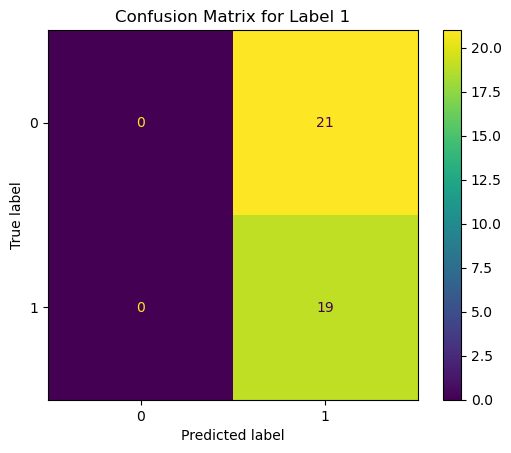

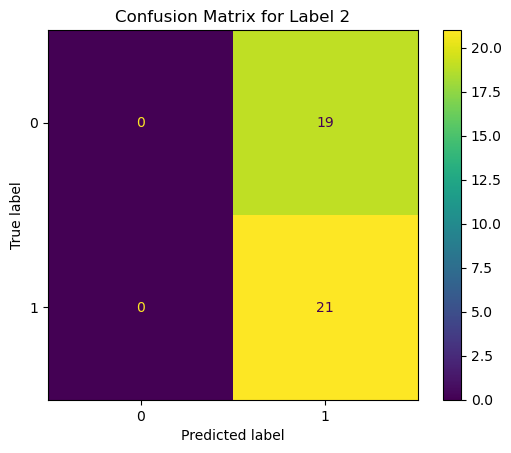

In [13]:
    from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
    import matplotlib.pyplot as plt

    # Convert to numpy arrays
    y_test_np = y_test.numpy()
    predicted_np = predicted.numpy()
    
    # Compute confusion matrix for each label
    confusion_matrices = []
    for i in range(y_test_np.shape[1]):  # Iterate over each label
        cm = confusion_matrix(y_test_np[:, i], predicted_np[:, i])
        confusion_matrices.append(cm)
    
    # Display confusion matrices
    for i, cm in enumerate(confusion_matrices):
        disp = ConfusionMatrixDisplay(confusion_matrix=cm)
        disp.plot()
        plt.title(f'Confusion Matrix for Label {i+1}')
        plt.show()

In [14]:
### DEPRECATED ###

In [15]:

# # Örnek tahminler
# sample_data = pd.DataFrame({
#     'file_name': ['ProtoSubject.java','BasicAnnotationProcessor.java'], #1:enhancement, 2:enhancement
#     'full_repo_name': ['google/truth','google/auto']
# })

# # Kodlama işlemleri
# sample_data['file_name_encoded'] = le_class.transform(sample_data['file_name'])
# sample_data['full_repo_name_encoded'] = le_repo.transform(sample_data['full_repo_name'])

# # Özellikleri hazırlama
# X_sample = sample_data[['file_name_encoded', 'full_repo_name_encoded']]
# X_sample = torch.tensor(X_sample.to_numpy(), dtype=torch.float32)

# with torch.no_grad():
#     model.eval()
#     test_outputs = model(X_sample)
#     predicted = torch.sigmoid(test_outputs)  # Sigmoid fonksiyonu uygulanmalı
#     print( predicted)
#     predicted = (predicted > 0.5).float()  # 0.5'ten büyük olanlar 1, diğerleri 0
#     print("after ceiling")
#     print( predicted)